In [ ]:
# Install KaggleHub
!pip install -q kagglehub

# Import the libraries
import kagglehub
import os

# Download the dataset
path = kagglehub.dataset_download(
    "gokulrajkmv/unemployment-in-india"
)

# Show the download location and available files
print("Dataset folder:", path)
print("\nFiles in the dataset:")

for file in os.listdir(path):
    print("-", file)

100%|██████████| 16.0k/16.0k [00:00<00:00, 15.7MB/s]

Extracting files...
Dataset folder: /root/.cache/kagglehub/datasets/gokulrajkmv/unemployment-in-india/versions/5

Files in the dataset:
- Unemployment in India.csv
- Unemployment_Rate_upto_11_2020.csv


In [ ]:
import pandas as pd
import os

# Load both CSV files
df1 = pd.read_csv(os.path.join(path, "Unemployment in India.csv"))
df2 = pd.read_csv(os.path.join(path, "Unemployment_Rate_upto_11_2020.csv"))

# Show the size and column names of each dataset
print("DATASET 1: Unemployment in India.csv")
print("Rows and columns:", df1.shape)
print("Column names:", df1.columns.tolist())

print("\nDATASET 2: Unemployment_Rate_upto_11_2020.csv")
print("Rows and columns:", df2.shape)
print("Column names:", df2.columns.tolist())

# Display the first five rows of each dataset
print("\nFirst 5 rows of Dataset 1:")
display(df1.head())

print("\nFirst 5 rows of Dataset 2:")
display(df2.head())

DATASET 1: Unemployment in India.csv
Rows and columns: (768, 7)
Column names: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

DATASET 2: Unemployment_Rate_upto_11_2020.csv
Rows and columns: (267, 9)
Column names: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

First 5 rows of Dataset 1:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



First 5 rows of Dataset 2:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


In [ ]:
# Remove extra spaces from column names
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# Inspect each dataset
for name, df in [("Dataset 1", df1), ("Dataset 2", df2)]:
    print(f"\n--- {name} ---")

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nData types:")
    print(df.dtypes)

    print("\nSample dates:")
    print(df["Date"].dropna().head().tolist())


--- Dataset 1 ---

Missing values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

Duplicate rows: 27

Data types:
Region                                      object
Date                                        object
Frequency                                   object
Estimated Unemployment Rate (%)            float64
Estimated Employed                         float64
Estimated Labour Participation Rate (%)    float64
Area                                        object
dtype: object

Sample dates:
[' 31-05-2019', ' 30-06-2019', ' 31-07-2019', ' 31-08-2019', ' 30-09-2019']

--- Dataset 2 ---

Missing values:
Region                                     0
Date                                       0
Frequenc

In [ ]:
# Make copies so the original DataFrames remain available
clean_df1 = df1.copy()
clean_df2 = df2.copy()

# Check completely empty rows in Dataset 1
empty_rows = clean_df1.isna().all(axis=1).sum()
print("Completely empty rows in Dataset 1:", empty_rows)

# Remove only rows that are completely empty
clean_df1 = clean_df1.dropna(how="all")

# Remove spaces around dates and convert them to datetime
for name, df in [("Dataset 1", clean_df1), ("Dataset 2", clean_df2)]:
    df["Date"] = pd.to_datetime(
        df["Date"].str.strip(),
        format="%d-%m-%Y",
        errors="coerce"
    )

    print(f"\n--- {name} after cleaning ---")
    print("Rows and columns:", df.shape)
    print("Dates that could not be converted:", df["Date"].isna().sum())
    print("Date range:", df["Date"].min(), "to", df["Date"].max())
    print("Duplicate rows remaining:", df.duplicated().sum())

Completely empty rows in Dataset 1: 28

--- Dataset 1 after cleaning ---
Rows and columns: (740, 7)
Dates that could not be converted: 0
Date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00
Duplicate rows remaining: 0

--- Dataset 2 after cleaning ---
Rows and columns: (267, 9)
Dates that could not be converted: 0
Date range: 2020-01-31 00:00:00 to 2020-10-31 00:00:00
Duplicate rows remaining: 0


In [ ]:
# Explore the cleaned first dataset
print("Number of regions:", clean_df1["Region"].nunique())

print("\nArea categories:")
print(clean_df1["Area"].value_counts())

print("\nUnemployment rate summary:")
print(clean_df1["Estimated Unemployment Rate (%)"].describe())

print("\nNumber of records per month:")
monthly_counts = clean_df1.groupby("Date").size()
print(monthly_counts)

Number of regions: 28

Area categories:
Area
Urban    381
Rural    359
Name: count, dtype: int64

Unemployment rate summary:
count    740.000000
mean      11.787946
std       10.721298
min        0.000000
25%        4.657500
50%        8.350000
75%       15.887500
max       76.740000
Name: Estimated Unemployment Rate (%), dtype: float64

Number of records per month:
Date
2019-05-31    54
2019-06-30    54
2019-07-31    54
2019-08-31    53
2019-09-30    52
2019-10-31    55
2019-11-30    55
2019-12-31    53
2020-01-31    53
2020-02-29    53
2020-03-31    52
2020-04-30    51
2020-05-31    51
2020-06-30    50
dtype: int64


Average recorded unemployment rate by month:


,Estimated Unemployment Rate (%)
Date,
2019-05-31,8.87
2019-06-30,9.30
2019-07-31,9.03
2019-08-31,9.64
2019-09-30,9.05
2019-10-31,9.90
2019-11-30,9.87
2019-12-31,9.50
2020-01-31,9.95


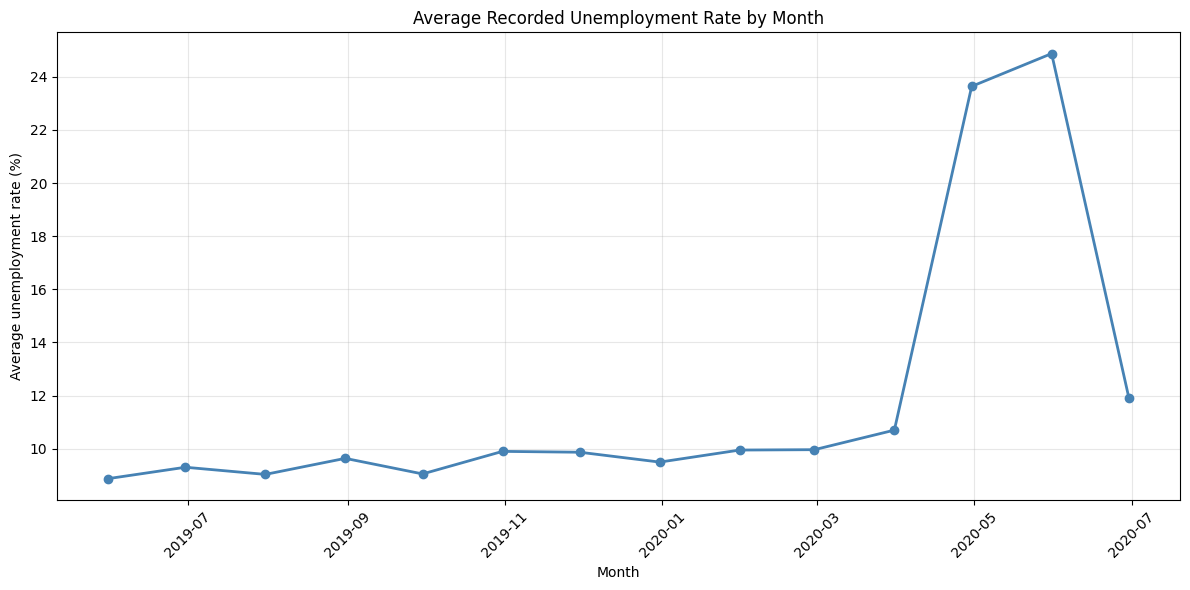

In [ ]:
import matplotlib.pyplot as plt

# Calculate the average recorded unemployment rate for each month
monthly_trend = (
    clean_df1.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

# Display the monthly averages
print("Average recorded unemployment rate by month:")
display(monthly_trend.round(2))

# Create the line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_trend.index,
    monthly_trend.values,
    marker="o",
    color="steelblue",
    linewidth=2
)

plt.title("Average Recorded Unemployment Rate by Month")
plt.xlabel("Month")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Monthly average unemployment rate by area:


Area,Rural,Urban
Date,,
2019-05-31,7.07,10.55
2019-06-30,8.20,10.33
2019-07-31,7.74,10.23
2019-08-31,8.50,10.73
2019-09-30,7.04,10.92
2019-10-31,9.05,10.72
2019-11-30,8.43,11.25
2019-12-31,8.23,10.63
2020-01-31,7.84,11.98


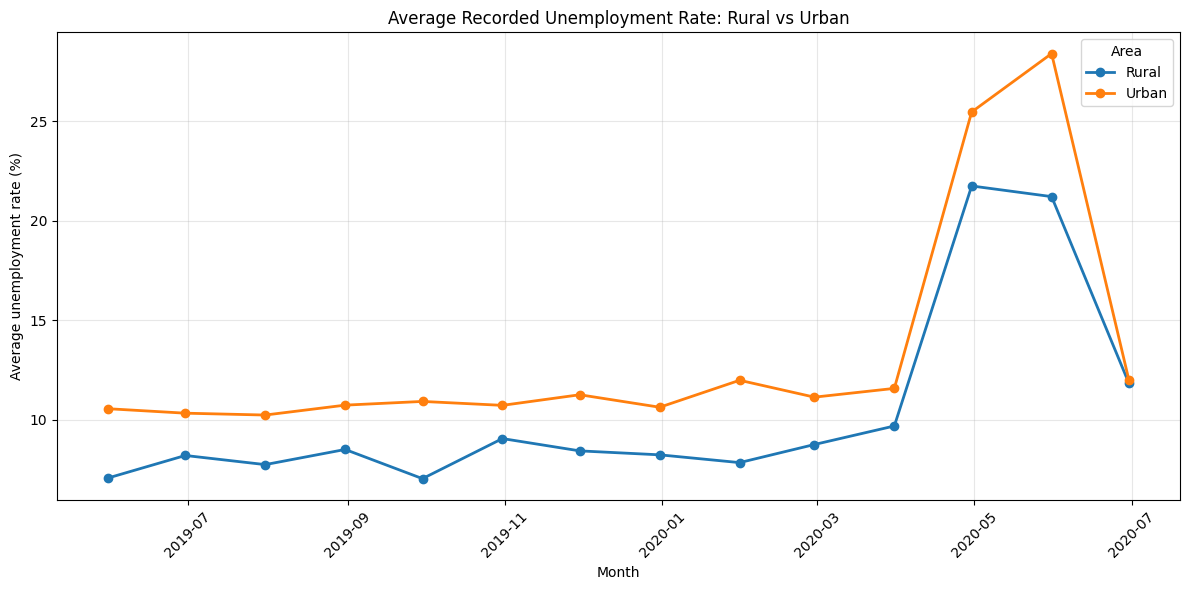

In [ ]:
# Calculate the monthly average for each area
area_trend = (
    clean_df1.groupby(["Date", "Area"])["Estimated Unemployment Rate (%)"]
    .mean()
    .unstack()
)

# Display the results
print("Monthly average unemployment rate by area:")
display(area_trend.round(2))

# Plot rural and urban trends
plt.figure(figsize=(12, 6))

for area in area_trend.columns:
    plt.plot(
        area_trend.index,
        area_trend[area],
        marker="o",
        linewidth=2,
        label=area
    )

plt.title("Average Recorded Unemployment Rate: Rural vs Urban")
plt.xlabel("Month")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Area")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Choose the two periods
before = clean_df1[
    clean_df1["Date"].between("2020-01-01", "2020-02-29")
].copy()

during = clean_df1[
    clean_df1["Date"].between("2020-04-01", "2020-05-31")
].copy()

rate_col = "Estimated Unemployment Rate (%)"

# Calculate each region-area average in each period
before_avg = (
    before.groupby(["Region", "Area"])[rate_col]
    .mean()
    .rename("Before (%)")
)

during_avg = (
    during.groupby(["Region", "Area"])[rate_col]
    .mean()
    .rename("During (%)")
)

# Keep region-area combinations present in both periods
comparison = pd.concat([before_avg, during_avg], axis=1).dropna()

# Calculate the difference in percentage points
comparison["Change (percentage points)"] = (
    comparison["During (%)"] - comparison["Before (%)"]
)

comparison = comparison.sort_values(
    "Change (percentage points)",
    ascending=False
)

print("Number of region-area combinations compared:", len(comparison))
print("\nLargest increases:")
display(comparison.head(10).round(2))

Number of region-area combinations compared: 52

Largest increases:


Before (%)  During (%)  Change (percentage points)
Region         Area                                                     
Puducherry     Urban        1.18       75.87                       74.70
               Rural        1.16       74.51                       73.35
Tamil Nadu     Rural        1.17       45.96                       44.78
Jharkhand      Urban       21.32       65.82                       44.51
               Rural        7.61       48.41                       40.80
Bihar          Rural        9.37       46.18                       36.80
Tamil Nadu     Urban        2.68       35.75                       33.07
Bihar          Urban       17.90       48.32                       30.42
Karnataka      Rural        3.34       28.44                       25.10
Andhra Pradesh Urban        6.38       28.60                       22.22

In [ ]:
# Show Puducherry's individual monthly records in the two periods
puducherry = clean_df1[
    (clean_df1["Region"].str.strip() == "Puducherry") &
    (clean_df1["Date"].isin(pd.to_datetime([
        "2020-01-31", "2020-02-29",
        "2020-04-30", "2020-05-31"
    ])))
]

print("Puducherry records:")
display(
    puducherry[["Region", "Area", "Date", rate_col]]
    .sort_values(["Area", "Date"])
)

# Count distinct months available for each region-area combination
before_months = (
    before.groupby(["Region", "Area"])["Date"]
    .nunique()
    .rename("Before months")
)

during_months = (
    during.groupby(["Region", "Area"])["Date"]
    .nunique()
    .rename("During months")
)

coverage = pd.concat([before_months, during_months], axis=1)

# Add coverage counts to our comparison
comparison_checked = comparison.join(coverage)

print("\nComparisons missing one or more months:")
incomplete = comparison_checked[
    (comparison_checked["Before months"] < 2) |
    (comparison_checked["During months"] < 2)
]

print("Number with incomplete coverage:", len(incomplete))
display(incomplete.round(2))

Puducherry records:


,Region,Area,Date,Estimated Unemployment Rate (%)
239,Puducherry,Rural,2020-01-31,0.58
240,Puducherry,Rural,2020-02-29,1.74
242,Puducherry,Rural,2020-04-30,74.51
624,Puducherry,Urban,2020-01-31,0.57
625,Puducherry,Urban,2020-02-29,1.78
627,Puducherry,Urban,2020-04-30,76.74
628,Puducherry,Urban,2020-05-31,75.00



Comparisons missing one or more months:
Number with incomplete coverage: 5


Before (%)  During (%)  Change (percentage points)  \
Region          Area                                                        
Puducherry      Rural        1.16       74.51                       73.35   
Assam           Rural        3.78        9.38                        5.60   
Goa             Urban        7.62       11.76                        4.14   
Jammu & Kashmir Urban       19.20       12.96                       -6.24   
                Rural       21.71        2.22                      -19.49   

                       Before months  During months  
Region          Area                                 
Puducherry      Rural            2.0            1.0  
Assam           Rural            2.0            1.0  
Goa             Urban            2.0            1.0  
Jammu & Kashmir Urban            2.0            1.0  
                Rural            2.0            1.0

Number of complete comparisons: 47


Before (%)  During (%)  Change (percentage points)  \
Region         Area                                                        
Puducherry     Urban        1.18       75.87                       74.70   
Tamil Nadu     Rural        1.17       45.96                       44.78   
Jharkhand      Urban       21.32       65.82                       44.51   
               Rural        7.61       48.41                       40.80   
Bihar          Rural        9.37       46.18                       36.80   
Tamil Nadu     Urban        2.68       35.75                       33.07   
Bihar          Urban       17.90       48.32                       30.42   
Karnataka      Rural        3.34       28.44                       25.10   
Andhra Pradesh Urban        6.38       28.60                       22.22   
Madhya Pradesh Urban        5.06       26.22                       21.15   

                      Before months  During months                   Label  
Region         Area                                                         
Puducherry     Urban            2.0            2.0      Puducherry - Urban  
Tamil Nadu     Rural            2.0            2.0      Tamil Nadu - Rural  
Jharkhand      Urban            2.0            2.0       Jharkhand - Urban  
               Rural            2.0            2.0       Jharkhand - Rural  
Bihar          Rural            2.0            2.0           Bihar - Rural  
Tamil Nadu     Urban            2.0            2.0      Tamil Nadu - Urban  
Bihar          Urban            2.0            2.0           Bihar - Urban  
Karnataka      Rural            2.0            2.0       Karnataka - Rural  
Andhra Pradesh Urban            2.0            2.0  Andhra Pradesh - Urban  
Madhya Pradesh Urban            2.0            2.0  Madhya Pradesh - Urban

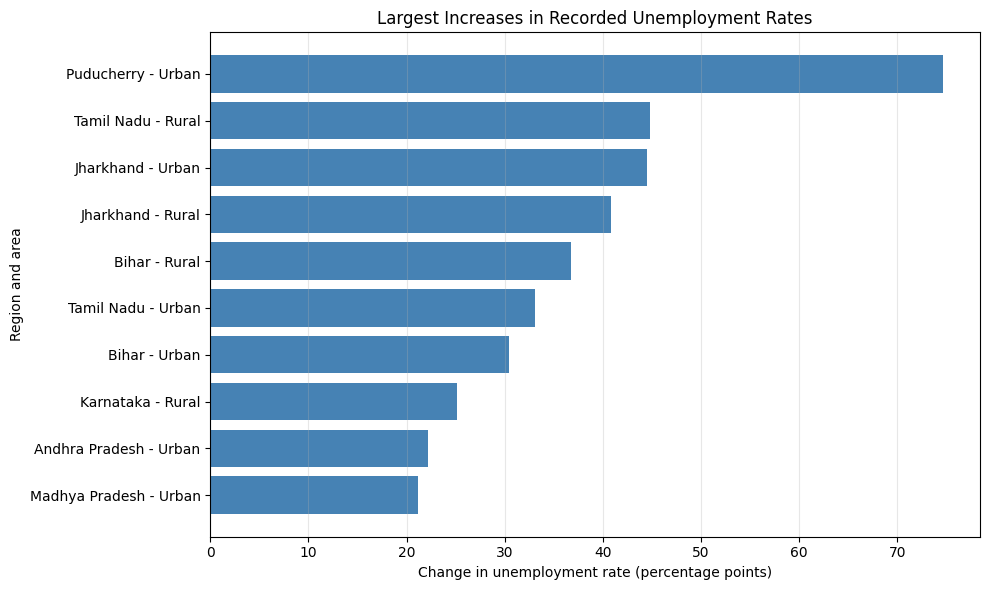

In [ ]:
# Keep comparisons with both months in each period
complete_comparison = comparison_checked[
    (comparison_checked["Before months"] == 2) &
    (comparison_checked["During months"] == 2)
].copy()

# Select the 10 largest increases
top_10 = complete_comparison.nlargest(
    10, "Change (percentage points)"
).copy()

# Create labels combining region and area
top_10["Label"] = [
    f"{region} - {area}"
    for region, area in top_10.index
]

print("Number of complete comparisons:", len(complete_comparison))
display(top_10.round(2))

# Plot the changes
plt.figure(figsize=(10, 6))

plt.barh(
    top_10["Label"],
    top_10["Change (percentage points)"],
    color="steelblue"
)

plt.gca().invert_yaxis()
plt.title("Largest Increases in Recorded Unemployment Rates")
plt.xlabel("Change in unemployment rate (percentage points)")
plt.ylabel("Region and area")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Dataset 2: Average recorded unemployment rate by month


,Estimated Unemployment Rate (%)
Date,
2020-01-31,9.20
2020-02-29,9.27
2020-03-31,10.78
2020-04-30,22.24
2020-05-31,23.24
2020-06-30,10.91
2020-07-31,9.83
2020-08-31,10.31
2020-09-30,8.71


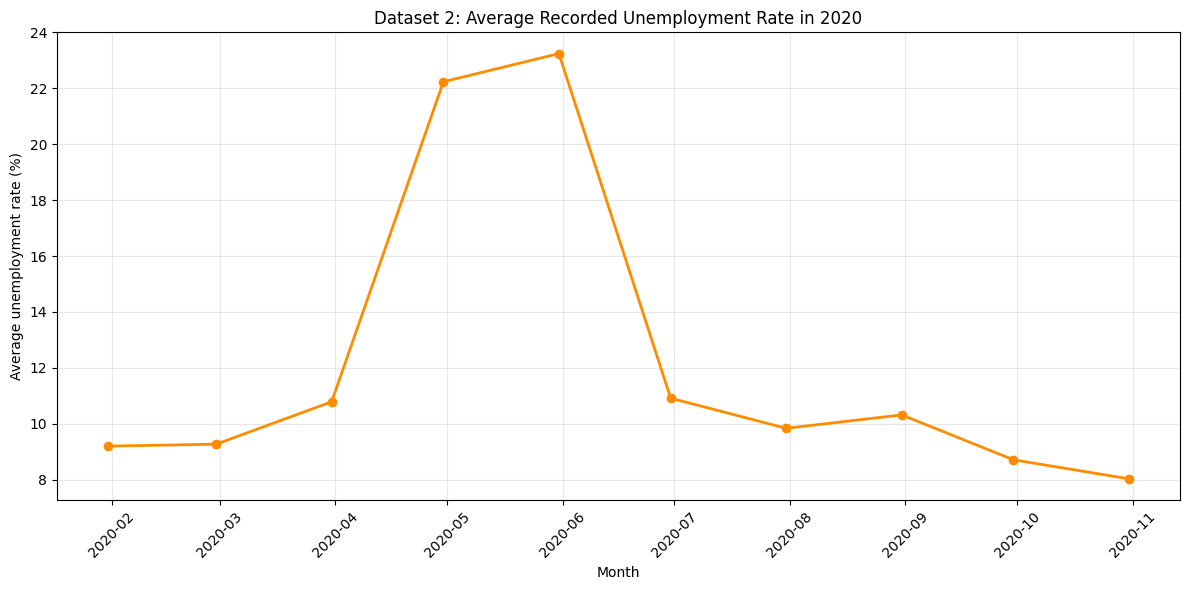

In [ ]:
# Calculate Dataset 2's average recorded rate by month
trend_2020 = (
    clean_df2.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

print("Dataset 2: Average recorded unemployment rate by month")
display(trend_2020.round(2))

# Create the chart
plt.figure(figsize=(12, 6))

plt.plot(
    trend_2020.index,
    trend_2020.values,
    marker="o",
    color="darkorange",
    linewidth=2
)

plt.title("Dataset 2: Average Recorded Unemployment Rate in 2020")
plt.xlabel("Month")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Create a working copy for the seasonal check
seasonal_df = clean_df1.copy()

# Extract year and month from each date
seasonal_df["Year"] = seasonal_df["Date"].dt.year
seasonal_df["Month"] = seasonal_df["Date"].dt.month

# Calculate the average recorded rate by year and month
year_month = seasonal_df.pivot_table(
    index="Month",
    columns="Year",
    values="Estimated Unemployment Rate (%)",
    aggfunc="mean"
)

# Keep only months that appear in both years
matching_months = year_month.dropna()

print("Months available in both years:")
display(matching_months.round(2))

# Calculate the difference in percentage points
matching_months = matching_months.copy()
matching_months["Change (percentage points)"] = (
    matching_months[2020] - matching_months[2019]
)

print("\nYear-over-year comparison:")
display(matching_months.round(2))

Months available in both years:


Year,2019,2020
Month,,
5,8.87,24.88
6,9.30,11.90



Year-over-year comparison:


Year,2019,2020,Change (percentage points)
Month,,,
5,8.87,24.88,16.0
6,9.30,11.90,2.6


## Key Findings

1. In Dataset 1, the average recorded unemployment rate rose from
   10.70% in March 2020 to 23.64% in April, peaking at 24.88%
   in May. It fell to 11.90% in June.

2. Both rural and urban averages increased sharply in April 2020.
   The urban average peaked at 28.40% in May, while the rural
   average peaked at 21.75% in April.

3. Among 47 region-area combinations with complete records for
   January, February, April, and May 2020, Puducherry urban had
   the largest increase in the comparison: 74.70 percentage points.
   This unusually large value should be verified against the
   original source.

4. Dataset 2 shows a similar rise and decline: its average recorded
   rate peaked at 23.24% in May 2020 and was 8.03% in October.

5. The data is insufficient to establish a reliable seasonal pattern.
   Only May and June are available for comparison across 2019 and 2020.

## Limitations

- Monthly averages are unweighted averages of available records,
  not necessarily national unemployment rates.
- The number and identity of regions represented can vary by month.
- The comparison is descriptive and does not prove that COVID-19
  caused the observed changes.
- The two datasets have different levels of detail and were
  analyzed separately.

## Policy Suggestions

1. **Prepare temporary income support during major disruptions.**
   The sharp rise in recorded unemployment rates in April and May
   2020 suggests a need to consider timely assistance for households
   affected by sudden employment disruptions.

2. **Investigate regional differences before targeting support.**
   Some region-area combinations showed much larger increases than
   others. Policymakers could examine local employment conditions
   and verify the data before deciding where support is most needed.

3. **Consider both rural and urban workers.**
   Recorded unemployment rates increased in both area categories.
   Employment support should account for the different needs of
   rural and urban communities.

4. **Monitor more than the unemployment rate.**
   Review employment and labour-force participation alongside
   unemployment, since changes in participation can affect how
   unemployment rates are interpreted.

5. **Improve long-term monitoring.**
   Collect consistent monthly data over several years to assess
   regional trends, recovery, and possible seasonal patterns.